# Wetteranalyse: Berlin

Dieses Notebook untersucht historische Tageswerte für Berlin: mittlere, minimale und maximale Temperatur sowie Niederschlag. Es betrachtet automatisch die letzten 14 Tage, für die die Wetterarchiv-Daten voraussichtlich vollständig vorliegen.

Die Koordinaten liegen im Berliner Stadtzentrum. Die Daten stammen von der frei zugänglichen [Open-Meteo-Archiv-API](https://open-meteo.com/). Zum Abruf wird eine Internetverbindung benötigt; ein API-Schlüssel ist nicht erforderlich.

## 1. Zeitraum festlegen

Das Wetterarchiv kann aktuelle Tage mit Verzögerung bereitstellen. Deshalb endet der Zeitraum sieben Tage vor heute und umfasst dann 14 Tage. Du kannst die Werte unten anpassen, falls du einen anderen Zeitraum untersuchen möchtest.

In [1]:
from datetime import datetime, timedelta
from zoneinfo import ZoneInfo

heute = datetime.now(ZoneInfo("Europe/Berlin")).date()
enddatum = heute - timedelta(days=7)
startdatum = enddatum - timedelta(days=13)

print(f"Untersuchungszeitraum: {startdatum:%d.%m.%Y} bis {enddatum:%d.%m.%Y}")

Untersuchungszeitraum: 13.10.2026 bis 26.10.2026


## 2. Wetterdaten abrufen

Die API liefert Tageswerte als JSON. Mit `urllib` und `json` verwenden wir dafür nur Python-Bibliotheken, die bereits mit Python kommen.

In [2]:
import json
from urllib.parse import urlencode
from urllib.request import urlopen

parameter = {
    "latitude": 52.52,
    "longitude": 13.405,
    "start_date": startdatum.isoformat(),
    "end_date": enddatum.isoformat(),
    "daily": "temperature_2m_mean,temperature_2m_min,temperature_2m_max,precipitation_sum",
    "timezone": "Europe/Berlin",
}
url = "https://archive-api.open-meteo.com/v1/archive?" + urlencode(parameter)

with urlopen(url, timeout=30) as antwort:
    wetter = json.load(antwort)

tageswerte = wetter["daily"]
print(f"{len(tageswerte['time'])} Tageswerte geladen.")

14 Tageswerte geladen.


## 3. Tageswerte im Diagramm

Die Linien zeigen Tagesminimum, Tagesmittel und Tagesmaximum der Temperatur in Grad Celsius. Die Balken zeigen den Niederschlag in Millimetern auf der rechten Achse. Fehlender Niederschlag wird im Diagramm als 0 mm dargestellt.

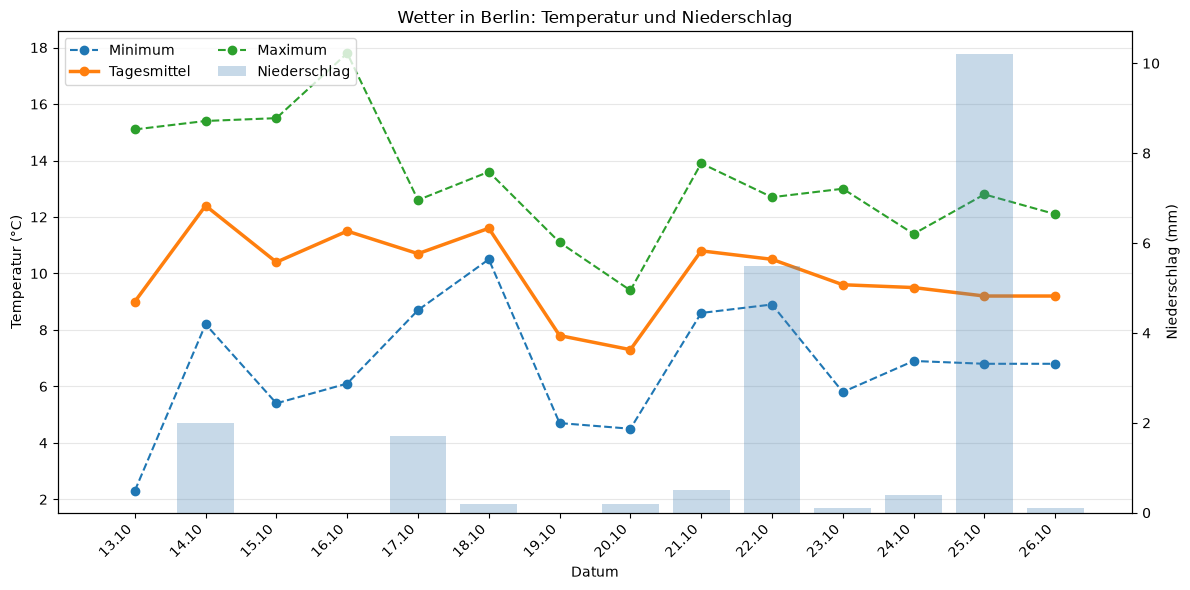

In [3]:
import matplotlib.pyplot as plt

tage = [f"{datum[8:10]}.{datum[5:7]}" for datum in tageswerte["time"]]
niederschlag = [wert if wert is not None else 0 for wert in tageswerte["precipitation_sum"]]

fig, temperatur_ax = plt.subplots(figsize=(12, 6))
niederschlag_ax = temperatur_ax.twinx()

niederschlag_ax.bar(
    tage,
    niederschlag,
    color="steelblue",
    alpha=0.3,
    label="Niederschlag",
)
linie_min, = temperatur_ax.plot(
    tage,
    tageswerte["temperature_2m_min"],
    marker="o",
    linestyle="--",
    label="Minimum",
)
linie_mittel, = temperatur_ax.plot(
    tage,
    tageswerte["temperature_2m_mean"],
    marker="o",
    linewidth=2.5,
    label="Tagesmittel",
)
linie_max, = temperatur_ax.plot(
    tage,
    tageswerte["temperature_2m_max"],
    marker="o",
    linestyle="--",
    label="Maximum",
)

temperatur_ax.set_title("Wetter in Berlin: Temperatur und Niederschlag")
temperatur_ax.set_xlabel("Datum")
temperatur_ax.set_ylabel("Temperatur (°C)")
niederschlag_ax.set_ylabel("Niederschlag (mm)")
temperatur_ax.grid(axis="y", alpha=0.3)

handles = [linie_min, linie_mittel, linie_max, niederschlag_ax.containers[0]]
labels = [handle.get_label() for handle in handles]
temperatur_ax.legend(handles, labels, loc="upper left", ncols=2)

fig.autofmt_xdate(rotation=45)
fig.tight_layout()
plt.show()

## 4. Zusammenfassung berechnen

Wir berechnen den Durchschnitt der Tagesmitteltemperaturen, die höchste Tageshöchsttemperatur, die niedrigste Tagestiefsttemperatur, die Niederschlagssumme und die Anzahl der Regentage. Fehlende Werte werden übersprungen.

In [4]:
mittelwerte = [wert for wert in tageswerte["temperature_2m_mean"] if wert is not None]
minima = [wert for wert in tageswerte["temperature_2m_min"] if wert is not None]
maxima = [wert for wert in tageswerte["temperature_2m_max"] if wert is not None]
niederschlaege = [wert for wert in tageswerte["precipitation_sum"] if wert is not None]

if mittelwerte:
    print(f"Durchschnittliche Tagesmitteltemperatur: {sum(mittelwerte) / len(mittelwerte):.1f} °C")
if maxima:
    print(f"Höchste Tageshöchsttemperatur: {max(maxima):.1f} °C")
if minima:
    print(f"Niedrigste Tagestiefsttemperatur: {min(minima):.1f} °C")
if niederschlaege:
    regentage = sum(1 for wert in niederschlaege if wert > 0)
    print(f"Niederschlag insgesamt: {sum(niederschlaege):.1f} mm")
    print(f"Tage mit Niederschlag: {regentage} von {len(niederschlaege)}")

Durchschnittliche Tagesmitteltemperatur: 10.0 °C
Höchste Tageshöchsttemperatur: 17.8 °C
Niedrigste Tagestiefsttemperatur: 2.3 °C
Niederschlag insgesamt: 20.9 mm
Tage mit Niederschlag: 10 von 14


## Einordnung

Die Kennzahlen beschreiben nur den ausgewählten Zeitraum und den verwendeten Standort im Berliner Zentrum. Sie sind keine Wettervorhersage. Niederschlagssummen beziehen sich auf den jeweiligen ganzen Tag.

### Übung

Ändere den Zeitraum in der ersten Codezelle und führe anschließend alle Zellen erneut aus. Vergleiche, wie sich Temperatur und Niederschlag verändern.